## 1. Régression linéaire

### Présentation

**Nom :** Régression linéaire (*Linear Regression*, moindres carrés ordinaires). **Famille :** régression (apprentissage supervisé). **Objectif :** prédire une variable cible numérique à partir de variables explicatives.

**Intuition et étapes :** données d'entrée (matrice X de 5 variables, cible y) → apprentissage : on cherche l'hyperplan qui passe au plus près des points, en minimisant la somme des carrés des erreurs → sortie : une prédiction numérique ŷ pour toute nouvelle observation.

**Formule essentielle :** ŷ = β₀ + β₁x₁ + … + β_p x_p, avec β̂ = argmin Σᵢ (yᵢ − ŷᵢ)².
- yᵢ : valeur réelle de l'observation i ; ŷᵢ : valeur prédite ; xⱼ : variable explicative j ; p : nombre de variables (ici 5).
- **Paramètres** (appris) : β₀ (constante) et β₁…β_p (coefficients). **Hyperparamètres** : aucun dans cette version de base.

**Avantages :** (1) simple, rapide et très interprétable (un coefficient = effet d'une variable) ; (2) sert de modèle de référence.
**Limites :** (1) ne capture que des relations linéaires ; (2) sensible aux valeurs extrêmes et à la colinéarité entre variables.

**Comment lire le schéma :** chaque point bleu est une observation. La droite rouge est le modèle appris. Les traits gris verticaux sont les erreurs (écart entre valeur réelle et valeur prédite) ; l'algorithme choisit la droite qui rend la somme des carrés de ces écarts la plus petite possible. Le schéma n'utilise que la variable 1 pour être lisible ; le modèle du notebook en utilise 5.

### Schéma explicatif

# Schéma : droite des moindres carrés et erreurs (résidus) sur la 1ère variable
from sklearn.linear_model import LinearRegression
x1 = X_reg[:, [0]]
droite = LinearRegression().fit(x1, y_reg)
pred = droite.predict(x1)
grille = np.linspace(x1.min(), x1.max(), 100).reshape(-1, 1)

plt.figure(figsize=(7, 4.5))
plt.scatter(x1, y_reg, s=12, alpha=.6, label='Observations (yᵢ)')
plt.plot(grille, droite.predict(grille), color='red', label='Droite ajustée (ŷ)')
plt.vlines(x1[:40, 0], y_reg[:40], pred[:40], color='gray', lw=.7, label='Erreurs (yᵢ − ŷᵢ), 40 premières')
plt.xlabel('Variable 1 (x₁)'); plt.ylabel('Cible (y)')
plt.title('Régression linéaire : minimiser la somme des carrés des erreurs')
plt.legend(); plt.show()

**Comment lire le schéma :** chaque point bleu est une observation. La droite rouge est le modèle appris. Les traits gris verticaux sont les erreurs (écart entre valeur réelle et valeur prédite) ; l'algorithme choisit la droite qui rend la somme des carrés de ces écarts la plus petite possible. Le schéma n'utilise que la variable 1 pour être lisible ; le modèle du notebook en utilise 5.

### Contextes d'utilisation

**Cas d'usage :** (1) **finance / gestion :** estimer le chiffre d'affaires d'une entreprise à partir de ses dépenses marketing, du nombre de clients et de la saison ; (2) **logistique :** prédire le coût de transport en fonction de la distance, du poids et du volume.

**Données et prérequis :** variables numériques (les variables catégorielles doivent être encodées), cible continue, relation approximativement linéaire, peu de colinéarité, pas ou peu de valeurs extrêmes.

**Cas peu approprié :** prédire une variable binaire (défaut / non-défaut) : les prédictions ne sont pas bornées entre 0 et 1, on utilise plutôt la régression logistique. Elle est aussi peu adaptée à une relation fortement non linéaire.

**Métriques adaptées :** MAE, RMSE, R².

### Analyse de l'expérience Python

- **Entrées :** `Xr_ent`, `yr_ent` (210 observations d'entraînement, 5 variables) pour l'apprentissage ; `Xr_test`, `yr_test` (70 observations) pour l'évaluation. Ce sont des **données synthétiques** (`make_regression`, bruit = 13).
- **Hyperparamètres :** aucun (`LinearRegression()` par défaut).
- **Sortie obtenue :** MAE = **9.35** (valeur obtenue à l'exécution avec `random_state=42`).
- **Ce que cela permet de conclure :** en moyenne, la prédiction s'écarte de la valeur réelle d'environ 9,35 unités sur ce jeu de test synthétique. Cette valeur est cohérente avec le bruit injecté (13) et sert de référence pour comparer les algorithmes 2 à 7.
- **Ce que cela ne permet pas de conclure :** rien sur des données réelles (jeu synthétique) ; une MAE seule ne dit pas si l'écart est grand ou petit sans comparaison à un autre modèle ; pas de conclusion sur R² ni RMSE, non calculés ici.

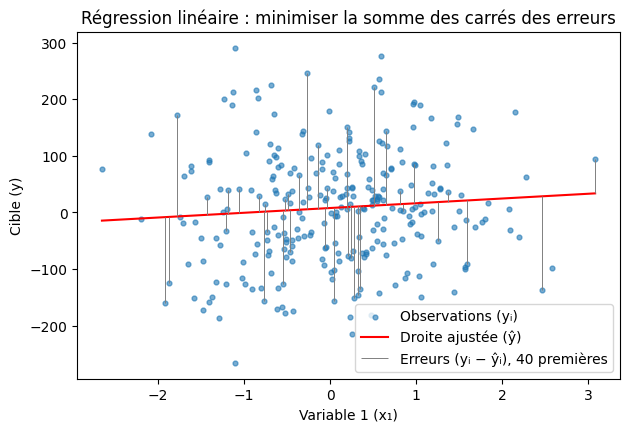

In [40]:
# Schéma : droite des moindres carrés et erreurs (résidus) sur la 1ère variable
from sklearn.linear_model import LinearRegression

x1 = X_reg[:, [0]]
droite = LinearRegression().fit(x1, y_reg)
pred = droite.predict(x1)
grille = np.linspace(x1.min(), x1.max(), 100).reshape(-1, 1)

plt.figure(figsize=(7, 4.5))
plt.scatter(x1, y_reg, s=12, alpha=.6, label='Observations (yᵢ)')
plt.plot(grille, droite.predict(grille), color='red', label='Droite ajustée (ŷ)')
plt.vlines(x1[:40, 0], y_reg[:40], pred[:40], color='gray', lw=.7, label='Erreurs (yᵢ − ŷᵢ), 40 premières')
plt.xlabel('Variable 1 (x₁)'); plt.ylabel('Cible (y)')
plt.title('Régression linéaire : minimiser la somme des carrés des erreurs')
plt.legend(); plt.show()

## 2. Ridge

### Présentation
**Nom :** Régression Ridge (Ridge Regression, régularisation L2). **Famille :** régression (apprentissage supervisé). **Objectif :** prédire une cible numérique comme la régression linéaire, mais en limitant la taille des coefficients pour éviter le surapprentissage et mieux gérer la colinéarité.

**Intuition et étapes :** données d'entrée (X de 5 variables, y) → standardisation des variables → apprentissage : on minimise l'erreur quadratique **plus une pénalité** qui punit les gros coefficients → sortie : une prédiction numérique ŷ.

**Formule essentielle :** β̂ = argmin [ Σᵢ (yᵢ − ŷᵢ)² + α Σⱼ βⱼ² ]

yᵢ : valeur réelle ; ŷᵢ : valeur prédite ; βⱼ : coefficient de la variable j ; α ≥ 0 : force de la pénalité. La constante β₀ n'est pas pénalisée.
**Paramètres (appris) :** β₀, β₁…β_p. **Hyperparamètre :** α (ici α = 1.0), à choisir par validation croisée, jamais sur le test.

**Avantages :** (1) stabilise les coefficients quand les variables sont corrélées ; (2) réduit la variance du modèle, donc le risque de surapprentissage. **Limites :** (1) ne met aucun coefficient exactement à zéro (pas de sélection de variables, contrairement à Lasso) ; (2) exige de standardiser les variables et de choisir α, sinon la pénalité est mal répartie.

### Schéma explicatif

In [41]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression, make_classification, make_blobs, load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, f1_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
GRAINE = 42
X_reg, y_reg = make_regression(n_samples=280, n_features=5, noise=13, random_state=GRAINE)
X_cls, y_cls = make_classification(n_samples=400, n_features=6, n_informative=4, n_redundant=0, random_state=GRAINE)
X_clu, etiquettes_reference = make_blobs(n_samples=240, centers=3, cluster_std=0.85, random_state=GRAINE)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg, y_reg, test_size=.25, random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls, y_cls, test_size=.25, stratify=y_cls, random_state=GRAINE)
print('Régression:',X_reg.shape,'Classification:',X_cls.shape)

Régression: (280, 5) Classification: (400, 6)


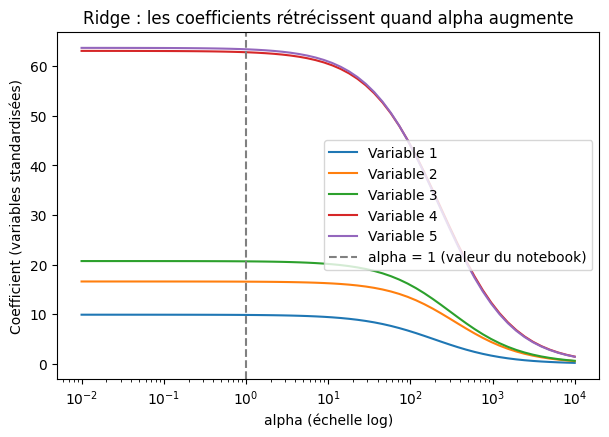

In [43]:
# Schéma : coefficients Ridge en fonction de alpha (données d'entraînement standardisées)
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

Z = StandardScaler().fit_transform(Xr_ent)
alphas = np.logspace(-2, 4, 60)
coefs = np.array([Ridge(alpha=a).fit(Z, yr_ent).coef_ for a in alphas])

plt.figure(figsize=(7, 4.5))
for j in range(coefs.shape[1]):
    plt.plot(alphas, coefs[:, j], label=f'Variable {j+1}')
plt.axvline(1.0, color='gray', ls='--', label='alpha = 1 (valeur du notebook)')
plt.xscale('log')
plt.xlabel('alpha (échelle log)'); plt.ylabel('Coefficient (variables standardisées)')
plt.title('Ridge : les coefficients rétrécissent quand alpha augmente')
plt.legend(); plt.show()

**Comment lire le schéma :** chaque courbe est le coefficient d'une variable. À gauche (alpha proche de 0), la pénalité est quasi nulle et on retrouve la régression linéaire. En allant vers la droite, la pénalité augmente et tous les coefficients se rapprochent de 0, mais sans jamais être exactement nuls. La ligne pointillée marque alpha = 1, la valeur utilisée dans le notebook : à cet endroit les coefficients sont encore très proches de ceux de la régression linéaire.

### Contextes d'utilisation
**Cas d'usage :** (1) finance / gestion : prédire le chiffre d'affaires ou le coût d'un projet à partir de nombreux indicateurs comptables corrélés entre eux (charges, effectifs, volume d'activité) ; (2) marketing : estimer les ventes à partir de plusieurs budgets publicitaires très liés (TV, web, affichage).

**Données et prérequis :** variables numériques standardisées (obligatoire), cible continue, relation à peu près linéaire, α choisi par validation croisée.

**Cas peu approprié :** quand on veut sélectionner un petit nombre de variables (Ridge garde toutes les variables, on préfère Lasso), ou quand la relation est fortement non linéaire.

**Métriques adaptées :** MAE, RMSE, R².

### Analyse de l'expérience Python
**Entrées :** Xr_ent, yr_ent (210 observations, 5 variables) pour l'apprentissage ; Xr_test, yr_test (70 observations) pour l'évaluation. Données synthétiques (make_regression, bruit = 13).
**Hyperparamètres :** alpha = 1.0, avec un `StandardScaler` placé dans le pipeline (ajusté sur l'entraînement uniquement, donc sans fuite d'information).
**Sortie obtenue :** MAE = 9.37 (avec random_state=42), contre 9.35 pour la régression linéaire (exemple 1).

**Ce que cela permet de conclure :** à alpha = 1, Ridge et la régression linéaire ont pratiquement la même erreur sur ce jeu de test. C'est cohérent : avec seulement 5 variables, peu de colinéarité et 210 observations, il y a peu de surapprentissage à corriger, et la pénalité est faible (voir schéma).
**Ce que cela ne permet pas de conclure :** que Ridge est meilleur ou moins bon que la régression linéaire (l'écart de 0.01 est négligeable sur un seul découpage de 70 observations) ; que alpha = 1 est optimal (il n'a pas été réglé par validation croisée) ; rien sur des données réelles (jeu synthétique) ; RMSE et R² n'ont pas été calculés ici.

## 3. Lasso

### Présentation
**Nom :** Régression Lasso (Lasso Regression, *Least Absolute Shrinkage and Selection Operator*, régularisation L1). **Famille :** régression (apprentissage supervisé). **Objectif :** prédire une cible numérique tout en **sélectionnant automatiquement les variables utiles**, car la pénalité L1 peut mettre certains coefficients exactement à zéro.

**Intuition et étapes :** données d'entrée (X de 5 variables, y) → standardisation des variables → apprentissage : on minimise l'erreur quadratique **plus une pénalité sur la somme des valeurs absolues** des coefficients → les coefficients des variables peu utiles sont ramenés à 0 → sortie : une prédiction numérique ŷ, faite avec un modèle plus simple.

**Formule essentielle :** β̂ = argmin [ (1/2n) Σᵢ (yᵢ − ŷᵢ)² + α Σⱼ |βⱼ| ]

n : nombre d'observations ; yᵢ : valeur réelle ; ŷᵢ : valeur prédite ; βⱼ : coefficient de la variable j ; α ≥ 0 : force de la pénalité. La constante β₀ n'est pas pénalisée.
**Paramètres (appris) :** β₀, β₁…β_p. **Hyperparamètres :** α (ici 0.1) et max_iter (ici 10000, nombre maximal d'itérations de l'algorithme de calcul).

**Avantages :** (1) sélectionne les variables (coefficients exactement nuls) et donne un modèle plus lisible ; (2) limite le surapprentissage quand il y a beaucoup de variables. **Limites :** (1) instable quand des variables sont très corrélées (il en garde une et écarte les autres, de façon arbitraire) ; (2) exige de standardiser les variables et de choisir α.

### Schéma explicatif

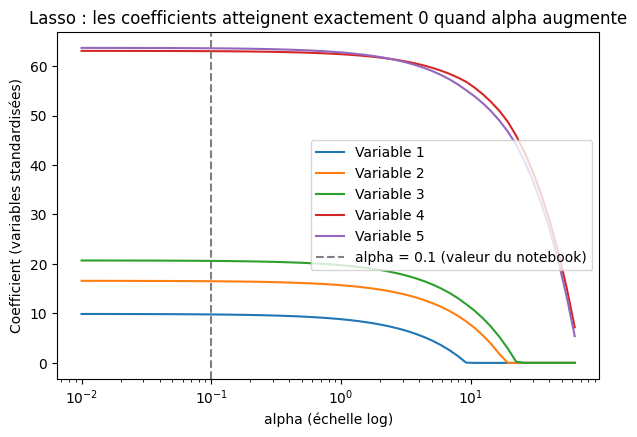

In [44]:
# Schéma : coefficients Lasso en fonction de alpha (données d'entraînement standardisées)
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

Z = StandardScaler().fit_transform(Xr_ent)
alphas = np.logspace(-2, 1.8, 60)
coefs = np.array([Lasso(alpha=a, max_iter=10000).fit(Z, yr_ent).coef_ for a in alphas])

plt.figure(figsize=(7, 4.5))
for j in range(coefs.shape[1]):
    plt.plot(alphas, coefs[:, j], label=f'Variable {j+1}')
plt.axvline(0.1, color='gray', ls='--', label='alpha = 0.1 (valeur du notebook)')
plt.xscale('log')
plt.xlabel('alpha (échelle log)'); plt.ylabel('Coefficient (variables standardisées)')
plt.title('Lasso : les coefficients atteignent exactement 0 quand alpha augmente')
plt.legend(); plt.show()



---
**Comment lire le schéma :** chaque courbe est le coefficient d'une variable. À gauche (alpha petit), la pénalité est faible et on retrouve presque la régression linéaire. En allant vers la droite, les coefficients diminuent, et **les variables les moins importantes tombent à 0 l'une après l'autre** (les courbes touchent l'axe horizontal et y restent). La ligne pointillée marque alpha = 0.1, la valeur du notebook : à cet endroit aucun coefficient n'est encore nul. Différence avec Ridge (algorithme 2) : chez Ridge, les courbes s'approchent de 0 sans jamais l'atteindre.

### Contextes d'utilisation
**Cas d'usage :** (1) finance / gestion : identifier, parmi des dizaines de ratios financiers, les quelques indicateurs qui expliquent vraiment la rentabilité ou le risque d'une entreprise ; (2) marketing : repérer les canaux publicitaires qui contribuent vraiment aux ventes parmi de nombreux canaux possibles.

**Données et prérequis :** variables numériques standardisées (obligatoire), cible continue, relation à peu près linéaire, α choisi par validation croisée. Utile surtout quand le nombre de variables est grand.

**Cas peu approprié :** quand plusieurs variables explicatives sont très corrélées et qu'on veut toutes les conserver et les interpréter : Lasso en garde une au hasard, on préfère alors Ridge. Il est aussi peu adapté à une relation fortement non linéaire.

**Métriques adaptées :** MAE, RMSE, R², et le nombre de coefficients non nuls pour juger la simplicité du modèle.


### Analyse de l'expérience Python
**Entrées :** Xr_ent, yr_ent (210 observations, 5 variables) pour l'apprentissage ; Xr_test, yr_test (70 observations) pour l'évaluation. Données synthétiques (make_regression, bruit = 13).
**Hyperparamètres :** alpha = 0.1, max_iter = 10000, avec un `StandardScaler` dans le pipeline (ajusté sur l'entraînement uniquement, donc sans fuite d'information).
**Sortie obtenue :** R² = 0.9860 sur le test (avec random_state=42), contre 0.9860 pour la régression linéaire. Aucun coefficient n'est nul avec alpha = 0.1.

**Ce que cela permet de conclure :** à alpha = 0.1, Lasso et la régression linéaire ont la même qualité de prédiction. Le modèle explique environ 98,6 % de la variance de la cible sur ce jeu de test synthétique. La pénalité est trop faible pour éliminer une variable ; le schéma montre qu'il faut un alpha d'environ 10 pour qu'une première variable passe à 0.
**Ce que cela ne permet pas de conclure :** que Lasso est meilleur que la régression linéaire (les R² sont identiques à la 4ᵉ décimale près) ; que alpha = 0.1 est optimal (non réglé par validation croisée) ; quelles variables sont « vraiment » importantes (aucune n'est éliminée ici) ; rien sur des données réelles (jeu synthétique) ; MAE et RMSE n'ont pas été calculés ici.

## 4. Régression polynomiale

### Présentation
**Nom :** Régression polynomiale (Polynomial Regression). **Famille :** régression (apprentissage supervisé). **Objectif :** prédire une cible numérique quand la relation avec les variables n'est pas une simple droite, en ajoutant des puissances et des produits des variables.

**Intuition et étapes :** données d'entrée (X de 5 variables, y) → standardisation → création de nouvelles variables (carrés xⱼ² et produits xⱼxₖ) → apprentissage d'un modèle linéaire (ici Ridge) sur ces variables enrichies → sortie : une prédiction ŷ qui suit une courbe. Le modèle reste linéaire par rapport à ses coefficients ; seule l'entrée est transformée.

**Formule essentielle (une seule variable, degré d) :** ŷ = β₀ + β₁x + β₂x² + … + β_d x^d.
x : variable explicative ; d : degré du polynôme ; βₖ : coefficient du terme x^k ; ŷ : valeur prédite. Avec 5 variables et d = 2, on obtient 20 variables (5 d'origine, 5 carrés et 10 produits croisés).
**Paramètres (appris) :** β₀…β_k. **Hyperparamètres :** degré d (ici 2) et alpha de Ridge (ici 10).

**Avantages :** (1) capte des courbures et des interactions entre variables ; (2) reste simple à calculer et à relier à la régression linéaire. **Limites :** (1) le nombre de variables explose avec le degré (5 → 20 → 55 → 125 pour d = 1 à 4) ; (2) risque fort de surapprentissage et prédictions instables aux bords des données quand d est grand.

### Schéma explicatif

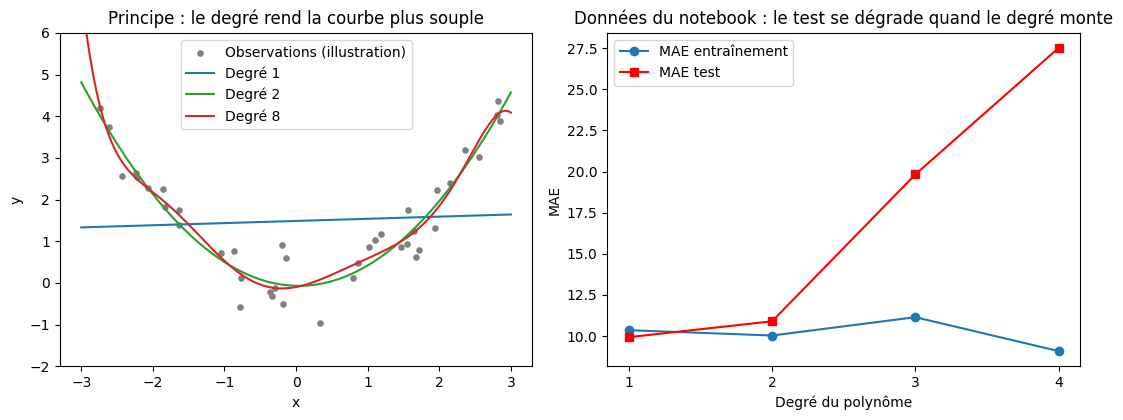

In [45]:
# Schéma : (gauche) effet du degré sur une courbe ; (droite) MAE selon le degré sur les données du notebook
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge, LinearRegression

g = np.random.default_rng(GRAINE)
xs = np.sort(g.uniform(-3, 3, 40)).reshape(-1, 1)
ys = 0.5*xs[:, 0]**2 + g.normal(0, 0.6, 40)
grille = np.linspace(-3, 3, 200).reshape(-1, 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
ax[0].scatter(xs, ys, s=14, color='gray', label='Observations (illustration)')
for d, c in [(1, 'tab:blue'), (2, 'tab:green'), (8, 'tab:red')]:
    mp = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(xs, ys)
    ax[0].plot(grille, mp.predict(grille), color=c, label=f'Degré {d}')
ax[0].set_ylim(-2, 6); ax[0].set_xlabel('x'); ax[0].set_ylabel('y')
ax[0].set_title('Principe : le degré rend la courbe plus souple'); ax[0].legend()

degres = [1, 2, 3, 4]; err_ent, err_test = [], []
for d in degres:
    mp = make_pipeline(StandardScaler(), PolynomialFeatures(d, include_bias=False), Ridge(alpha=10)).fit(Xr_ent, yr_ent)
    err_ent.append(mean_absolute_error(yr_ent, mp.predict(Xr_ent)))
    err_test.append(mean_absolute_error(yr_test, mp.predict(Xr_test)))
ax[1].plot(degres, err_ent, 'o-', label='MAE entraînement')
ax[1].plot(degres, err_test, 's-', color='red', label='MAE test')
ax[1].set_xticks(degres); ax[1].set_xlabel('Degré du polynôme'); ax[1].set_ylabel('MAE')
ax[1].set_title("Données du notebook : le test se dégrade quand le degré monte"); ax[1].legend()
plt.tight_layout(); plt.show()

**Comment lire le schéma :** *à gauche*, illustration pédagogique sur des points simulés qui suivent une parabole (ce ne sont pas les données du notebook) : le degré 1 (droite bleue) est trop rigide, le degré 2 (verte) épouse bien la forme, le degré 8 (rouge) est trop souple et colle au bruit. *À droite*, données réelles du notebook (synthétiques) : en rouge l'erreur sur le test, en bleu l'erreur sur l'entraînement. Quand le degré augmente, l'erreur de test monte nettement (surapprentissage) alors que l'erreur d'entraînement ne s'améliore pas de façon régulière.

### Contextes d'utilisation
**Cas d'usage :** (1) finance / gestion : modéliser le coût de production en fonction du volume quand il existe des économies ou déséconomies d'échelle (relation courbe) ; (2) logistique : estimer le temps de livraison selon la distance et le trafic, avec une accélération des retards quand le trafic augmente.

**Données et prérequis :** variables numériques standardisées, cible continue, relation courbe visible, peu de variables (le nombre de termes explose), régularisation (Ridge ou Lasso) et degré choisis par validation croisée.

**Cas peu approprié :** beaucoup de variables ou degré élevé (trop de termes pour le nombre d'observations), ou prédiction hors de la plage des données d'entraînement (un polynôme extrapole mal). Elle est aussi inutile quand la relation est déjà linéaire, comme c'est le cas ici.

**Métriques adaptées :** MAE, RMSE, R², en comparant l'erreur d'entraînement et de test pour détecter le surapprentissage.

### Analyse de l'expérience Python
**Entrées :** Xr_ent, yr_ent (210 observations, 5 variables) pour l'apprentissage ; Xr_test, yr_test (70 observations) pour l'évaluation. Données synthétiques (make_regression, bruit = 13).
**Hyperparamètres :** degré = 2 (ce qui produit 20 variables), alpha de Ridge = 10, `StandardScaler` dans le pipeline (ajusté sur l'entraînement uniquement, donc sans fuite d'information).
**Sortie obtenue :** MAE = 10.90 sur le test (avec random_state=42), contre 9.35 pour la régression linéaire (exemple 1). Sur l'entraînement, la MAE est de 10.03.

**Ce que cela permet de conclure :** sur ce jeu, la version polynomiale est un peu moins bonne que la régression linéaire. C'est cohérent : les données ont été générées avec une relation linéaire, donc les termes de degré 2 n'apportent rien et ajoutent surtout du bruit. Le schéma de droite montre aussi que l'erreur de test monte avec le degré (9.93, 10.90, 19.82, 27.52 pour les degrés 1 à 4).
**Ce que cela ne permet pas de conclure :** que la régression polynomiale est mauvaise en général (elle serait utile sur des données réellement courbes) ; que le degré 2 est optimal ici (non réglé par validation croisée) ; que la différence de 1,5 point est stable (un seul découpage de 70 observations) ; rien sur des données réelles (jeu synthétique) ; RMSE et R² n'ont pas été calculés ici.

## 5. Arbre de régression

### Q1. Présentation
**Nom :** Arbre de régression (Regression Tree, CART). **Famille :** régression (apprentissage supervisé). **Objectif :** prédire une cible numérique en découpant les données par une suite de questions simples (« x₄ ≤ seuil ? »), chaque groupe final recevant une valeur constante.

**Intuition et étapes :** données d'entrée (X de 5 variables, y) → apprentissage : à chaque nœud, on choisit la variable et le seuil qui séparent les données en deux groupes les plus homogènes possible, puis on recommence dans chaque groupe jusqu'à la profondeur maximale → sortie : pour une nouvelle observation, on descend l'arbre jusqu'à une feuille et on renvoie la **moyenne des y** de cette feuille.

**Critère essentiel :** à chaque nœud, on minimise Σ_{i∈G} (yᵢ − ȳ_G)² + Σ_{i∈D} (yᵢ − ȳ_D)².
yᵢ : valeur réelle de l'observation i ; G et D : groupes de gauche et de droite après le découpage ; ȳ_G, ȳ_D : moyenne des y dans chaque groupe (c'est la valeur prédite).
**Paramètres (appris) :** variables et seuils de chaque nœud, valeurs des feuilles. **Hyperparamètres :** max_depth (ici 5), random_state (ici 42).

**Avantages :** (1) très lisible : on peut suivre les règles de décision ; (2) pas besoin de standardiser et capte des relations non linéaires. **Limites :** (1) prédiction en escalier, peu adaptée à une relation linéaire continue ; (2) instable et sujet au surapprentissage quand l'arbre est profond.

### Q2. Schéma explicatif

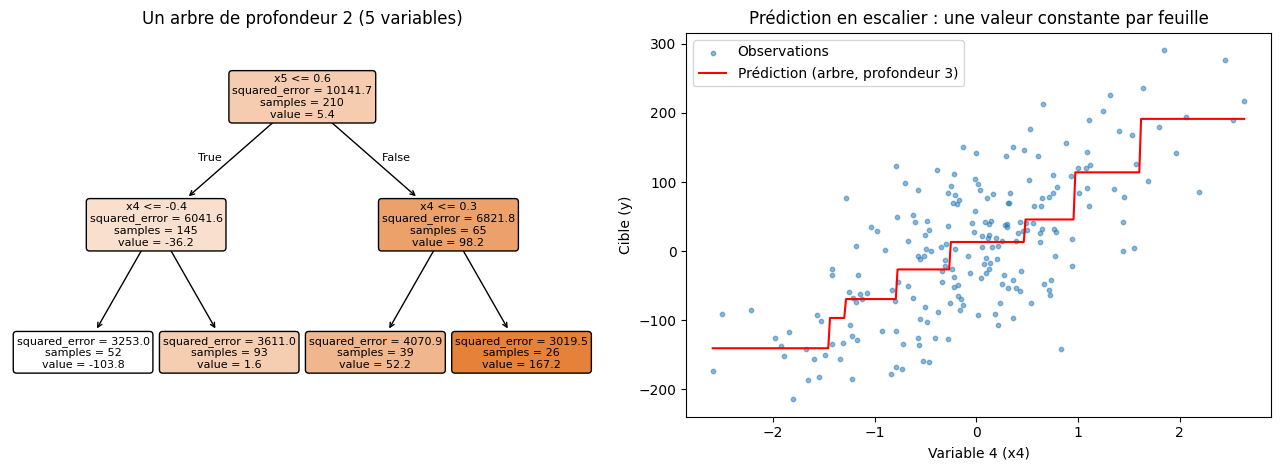

In [46]:
# Schéma : (gauche) un petit arbre ; (droite) prédiction en escalier sur une variable
from sklearn.tree import DecisionTreeRegressor, plot_tree

petit = DecisionTreeRegressor(max_depth=2, random_state=GRAINE).fit(Xr_ent, yr_ent)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
plot_tree(petit, feature_names=[f'x{j+1}' for j in range(5)], filled=True, rounded=True, precision=1, ax=ax[0], fontsize=8)
ax[0].set_title('Un arbre de profondeur 2 (5 variables)')

x4 = Xr_ent[:, [3]]
a1 = DecisionTreeRegressor(max_depth=3, random_state=GRAINE).fit(x4, yr_ent)
grille = np.linspace(x4.min(), x4.max(), 300).reshape(-1, 1)
ax[1].scatter(x4, yr_ent, s=10, alpha=.5, label='Observations')
ax[1].plot(grille, a1.predict(grille), color='red', label='Prédiction (arbre, profondeur 3)')
ax[1].set_xlabel('Variable 4 (x4)'); ax[1].set_ylabel('Cible (y)')
ax[1].set_title('Prédiction en escalier : une valeur constante par feuille'); ax[1].legend()
plt.tight_layout(); plt.show()

**Comment lire le schéma :** *à gauche*, chaque rectangle est un nœud. La première ligne donne la question (ex. « x4 ≤ valeur ») : on va à gauche si c'est vrai, à droite sinon. `squared_error` est l'erreur du groupe, `samples` le nombre d'observations et `value` la valeur prédite (moyenne des y du groupe) ; la couleur est plus foncée quand cette valeur est plus élevée. Les rectangles du bas sont les feuilles. *À droite*, l'arbre n'utilise que la variable 4 : sa prédiction (ligne rouge) est un escalier, avec une marche par feuille. Les deux figures sont des arbres plus petits (profondeur 2 et 3) que celui de l'expérience (profondeur 5), pour rester lisibles.

### Q3. Contextes d'utilisation
**Cas d'usage :** (1) finance / gestion : estimer le montant d'un sinistre ou d'un crédit selon des règles lisibles (âge du client, ancienneté, type de contrat) que l'on peut expliquer à un décideur ; (2) logistique : prédire le délai de livraison selon la zone, le transporteur et le jour de la semaine.

**Données et prérequis :** variables numériques ou catégorielles encodées, cible continue, pas de standardisation nécessaire, profondeur ou taille minimale des feuilles à contrôler pour limiter le surapprentissage.

**Cas peu approprié :** quand la relation est linéaire et continue (comme ici), car l'arbre l'approche par des marches d'escalier et nécessite beaucoup de feuilles pour la suivre. Il extrapole aussi très mal hors de la plage des données.

**Métriques adaptées :** MAE, RMSE, R², en comparant l'erreur d'entraînement et de test pour détecter le surapprentissage.

### Q4. Analyse de l'expérience Python
**Entrées :** Xr_ent, yr_ent (210 observations, 5 variables) pour l'apprentissage ; Xr_test, yr_test (70 observations) pour l'évaluation. Données synthétiques (make_regression, bruit = 13).
**Hyperparamètres :** max_depth = 5, random_state = 42. L'arbre obtenu a 31 feuilles.
**Sortie obtenue :** MAE = 37.72 sur le test, contre 20.50 sur l'entraînement. Pour comparaison, la régression linéaire (exemple 1) obtient 9.35 sur le même test.

**Ce que cela permet de conclure :** sur ce jeu, l'arbre est nettement moins précis que la régression linéaire (environ 4 fois plus d'erreur). C'est cohérent : les données ont été générées avec une relation linéaire, que l'arbre approche par un escalier. L'écart entre l'erreur d'entraînement (20.50) et de test (37.72) montre aussi un début de surapprentissage. Les variables 4 et 5 portent la quasi-totalité de l'importance (environ 0.42 et 0.52 sur 1).
**Ce que cela ne permet pas de conclure :** que les arbres sont mauvais en général (ils sont utiles pour des relations non linéaires ou des règles par seuils) ; que max_depth = 5 est le bon réglage (non réglé par validation croisée) ; rien sur des données réelles (jeu synthétique) ; RMSE et R² n'ont pas été calculés ici.

## 6. Forêt aléatoire — régression

### Q1. Présentation
**Nom :** Forêt aléatoire pour la régression (Random Forest Regressor). **Famille :** régression (apprentissage supervisé, méthode d'ensemble). **Objectif :** prédire une cible numérique en moyennant les prédictions de nombreux arbres de régression, pour obtenir un modèle plus stable qu'un arbre seul.

**Intuition et étapes :** données d'entrée (X de 5 variables, y) → apprentissage : on tire B échantillons avec remise (bootstrap) et on entraîne un arbre sur chacun, en ne considérant à chaque découpage qu'un sous-ensemble aléatoire de variables → sortie : la **moyenne** des prédictions des B arbres.

**Formule essentielle :** ŷ(x) = (1/B) Σ_{b=1}^{B} T_b(x).
x : nouvelle observation ; B : nombre d'arbres ; T_b(x) : prédiction de l'arbre b ; ŷ(x) : prédiction finale de la forêt.
**Paramètres (appris) :** les découpages et les valeurs des feuilles de chaque arbre. **Hyperparamètres :** n_estimators = B (ici 80), random_state (ici 42), et d'autres non précisés ici qui gardent leur valeur par défaut (profondeur, nombre de variables testées par découpage).

**Avantages :** (1) bien plus stable et précis qu'un arbre seul, car la moyenne réduit la variance ; (2) capte des relations non linéaires et fournit l'importance des variables. **Limites :** (1) moins interprétable qu'un arbre (80 arbres à lire) et plus coûteux en calcul ; (2) prédiction en escalier, donc peu adaptée à une relation linéaire continue, et extrapole mal hors de la plage des données.

### Q2. Schéma explicatif

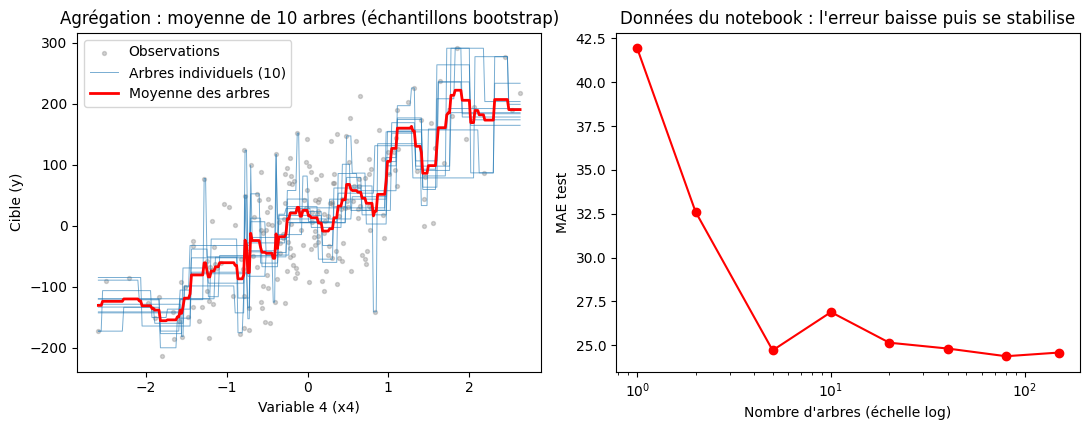

In [47]:
# Schéma : (gauche) moyenne de 10 arbres ; (droite) MAE test selon le nombre d'arbres
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

x4 = Xr_ent[:, [3]]; g = np.random.default_rng(GRAINE)
grille = np.linspace(x4.min(), x4.max(), 300).reshape(-1, 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].scatter(x4, yr_ent, s=8, alpha=.35, color='gray', label='Observations')
preds = []
for b in range(10):
    idx = g.integers(0, len(x4), len(x4))
    t = DecisionTreeRegressor(max_depth=4, random_state=b).fit(x4[idx], yr_ent[idx])
    p = t.predict(grille); preds.append(p)
    ax[0].plot(grille, p, lw=.7, alpha=.6, color='tab:blue', label='Arbres individuels (10)' if b == 0 else None)
ax[0].plot(grille, np.mean(preds, axis=0), color='red', lw=2, label='Moyenne des arbres')
ax[0].set_xlabel('Variable 4 (x4)'); ax[0].set_ylabel('Cible (y)')
ax[0].set_title('Agrégation : moyenne de 10 arbres (échantillons bootstrap)'); ax[0].legend()

nb = [1, 2, 5, 10, 20, 40, 80, 150]; err = []
for n in nb:
    f = RandomForestRegressor(n_estimators=n, random_state=GRAINE).fit(Xr_ent, yr_ent)
    err.append(mean_absolute_error(yr_test, f.predict(Xr_test)))
ax[1].plot(nb, err, 'o-', color='red'); ax[1].set_xscale('log')
ax[1].set_xlabel("Nombre d'arbres (échelle log)"); ax[1].set_ylabel('MAE test')
ax[1].set_title("Données du notebook : l'erreur baisse puis se stabilise")
plt.tight_layout(); plt.show()

**Comment lire le schéma :** *à gauche*, chaque courbe bleue fine est la prédiction d'un arbre entraîné sur un échantillon bootstrap différent : elles varient beaucoup d'un arbre à l'autre. La courbe rouge épaisse est leur moyenne : elle est plus lisse et plus stable. Cette figure n'utilise que la variable 4 pour rester lisible (la forêt de l'expérience en utilise 5). *À droite*, sur les données du notebook, l'erreur de test est la plus forte avec un seul arbre, puis elle diminue vite et se stabilise autour de 24–25 à partir de quelques dizaines d'arbres. Ce graphe sert uniquement à illustrer le principe : il ne sert pas à régler n_estimators sur le test.

### Q3. Contextes d'utilisation
**Cas d'usage :** (1) finance / gestion : estimer le prix d'un bien immobilier ou la valeur d'un portefeuille à partir de nombreuses caractéristiques, avec des interactions non linéaires entre variables ; (2) marketing / logistique : prévoir la demande d'un produit selon le prix, la saison, la promotion et le lieu.

**Données et prérequis :** variables numériques ou catégorielles encodées, cible continue, pas de standardisation nécessaire, un nombre d'arbres suffisant (quelques dizaines à quelques centaines).

**Cas peu approprié :** relation linéaire simple avec peu de variables (comme ici : la régression linéaire est meilleure et plus simple), ou besoin d'un modèle très interprétable ou de prédictions hors de la plage des données d'entraînement.

**Métriques adaptées :** MAE, RMSE, R², en comparant l'erreur d'entraînement et de test.

### Q4. Analyse de l'expérience Python
**Entrées :** Xr_ent, yr_ent (210 observations, 5 variables) pour l'apprentissage ; Xr_test, yr_test (70 observations) pour l'évaluation. Données synthétiques (make_regression, bruit = 13).
**Hyperparamètres :** n_estimators = 80, random_state = 42 (les autres gardent leur valeur par défaut).
**Sortie obtenue :** MAE = 24.37 sur le test, contre 9.04 sur l'entraînement.

**Ce que cela permet de conclure :** la forêt (24.37) est nettement meilleure que l'arbre de régression seul (37.72, exemple 5), ce qui illustre l'effet de la moyenne sur la variance. Elle reste pourtant moins bonne que la régression linéaire (9.35, exemple 1) : les données sont linéaires, ce que des arbres approchent mal. L'écart entre l'erreur d'entraînement (9.04) et de test (24.37) indique un surapprentissage notable. Comme pour l'arbre, les variables 4 et 5 dominent l'importance (environ 0.44 et 0.47).
**Ce que cela ne permet pas de conclure :** que la forêt est moins bonne que la régression linéaire en général (cela dépend de la nature des données) ; que 80 arbres ou les réglages par défaut sont optimaux (non réglés par validation croisée) ; rien sur des données réelles (jeu synthétique) ; RMSE et R² n'ont pas été calculés ici.

## 8. Régression logistique

### Q1. Présentation
**Nom :** Régression logistique (Logistic Regression). **Famille :** classification (apprentissage supervisé). **Objectif :** prédire la classe d'une observation (ici 0 ou 1) en estimant la **probabilité** d'appartenir à la classe 1.

**Intuition et étapes :** données d'entrée (X de 6 variables standardisées, y binaire) → apprentissage : on cherche les coefficients qui rendent les probabilités prédites les plus proches des classes réelles (maximum de vraisemblance) → sortie : une probabilité entre 0 et 1, transformée en classe (1 si la probabilité dépasse 0,5, sinon 0).

**Formule essentielle :** P(y = 1 | x) = 1 / (1 + e^{−z}), avec z = β₀ + β₁x₁ + … + β_p x_p.
x : observation ; xⱼ : variable j ; p : nombre de variables (ici 6) ; z : score linéaire ; P(y = 1 | x) : probabilité de la classe 1.
**Paramètres (appris) :** β₀ et β₁…β_p. **Hyperparamètres :** max_iter (ici 1000, nombre maximal d'itérations du calcul), random_state (ici 42) ; la force de régularisation C garde sa valeur par défaut.

**Avantages :** (1) donne une probabilité, pas seulement une classe, et ses coefficients sont interprétables ; (2) rapide, simple, et sert de bon modèle de référence en classification. **Limites :** (1) la frontière de décision est linéaire, donc il ne capte pas les relations non linéaires sans variables supplémentaires ; (2) sensible à l'échelle des variables (d'où la standardisation) et aux variables très corrélées.

### Q2. Schéma explicatif

In [47]:
# Schéma : (gauche) fonction sigmoïde ; (droite) probabilités prédites sur le jeu de test
from sklearn.linear_model import LogisticRegression

z = np.linspace(-6, 6, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].plot(z, 1/(1+np.exp(-z)), color='tab:blue')
ax[0].axhline(.5, color='gray', ls='--'); ax[0].axvline(0, color='gray', ls=':')
ax[0].set_xlabel('Score z = β₀ + β₁x₁ + … + β_p x_p'); ax[0].set_ylabel('Probabilité P(y = 1)')
ax[0].set_title('Fonction sigmoïde : transforme un score en probabilité')

m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=GRAINE)).fit(Xc_ent, yc_ent)
proba = m.predict_proba(Xc_test)[:, 1]
ordre = np.argsort(proba)
couleurs = np.where(yc_test[ordre] == 1, 'tab:red', 'tab:blue')
ax[1].scatter(range(len(ordre)), proba[ordre], c=couleurs, s=14)
ax[1].axhline(.5, color='gray', ls='--')
ax[1].scatter([], [], c='tab:red', label='Classe réelle 1'); ax[1].scatter([], [], c='tab:blue', label='Classe réelle 0')
ax[1].set_xlabel('Observations de test (triées par probabilité)'); ax[1].set_ylabel('Probabilité prédite P(y = 1)')
ax[1].set_title('Données du notebook : probabilités prédites sur le test'); ax[1].legend()
plt.tight_layout(); plt.show()

**Comment lire le schéma :** *à gauche*, la courbe en S (sigmoïde) transforme n'importe quel score z en une probabilité entre 0 et 1. Quand z = 0, la probabilité vaut 0,5 : c'est le seuil de décision (ligne pointillée). *À droite*, chaque point est une observation du jeu de test, classée de la plus faible à la plus forte probabilité prédite. Les points bleus (classe réelle 0) devraient se situer sous la ligne 0,5 et les rouges (classe réelle 1) au-dessus : les points du « mauvais » côté sont les erreurs du modèle (20 sur 100 ici).

### Q3. Contextes d'utilisation
**Cas d'usage :** (1) finance : estimer la probabilité de défaut de paiement d'un client à partir de son revenu, de son endettement et de son historique de crédit (scoring) ; (2) marketing : prédire si un client va répondre à une campagne ou résilier son abonnement (churn).

**Données et prérequis :** variables numériques standardisées (variables catégorielles encodées), cible binaire (ou multiclasse), relation à peu près linéaire entre les variables et le logit (log-odds), peu de colinéarité.

**Cas peu approprié :** frontière de décision fortement non linéaire (par exemple, une classe entourée par l'autre), pour laquelle on préfère SVM à noyau, forêt aléatoire ou boosting. Elle est aussi peu fiable quand les classes sont très déséquilibrées si l'on ne regarde que l'exactitude.

**Métriques adaptées :** F1, précision, rappel, ROC-AUC ou PR-AUC (surtout si les classes sont déséquilibrées).

### Q4. Analyse de l'expérience Python
**Entrées :** Xc_ent, yc_ent (300 observations, 6 variables) pour l'apprentissage ; Xc_test, yc_test (100 observations) pour l'évaluation. Données synthétiques (make_classification), classes équilibrées (50 / 50 sur le test), découpage stratifié.
**Hyperparamètres :** max_iter = 1000, random_state = 42, avec un `StandardScaler` dans le pipeline (ajusté sur l'entraînement uniquement, donc sans fuite d'information).
**Sortie obtenue :** F1 = 0.811 sur le test (avec random_state=42). En complément, l'exactitude est de 0.80, la précision de 0.768 et le rappel de 0.86.

**Ce que cela permet de conclure :** le modèle classe correctement environ 80 % des observations de test. Il détecte 86 % des vraies observations de la classe 1 (rappel), mais environ 23 % de ses alertes « classe 1 » sont de fausses alertes (précision 0.768). Les coefficients les plus élevés en valeur absolue (variables 6, 3 et 1) sont celles qui pèsent le plus dans la décision. Le F1 d'entraînement (0.738) est inférieur à celui du test (0.811) : il n'y a pas de surapprentissage, et l'écart reflète surtout la petite taille du test.
**Ce que cela ne permet pas de conclure :** que 0.811 est un « bon » score en soi (il faut le comparer aux autres algorithmes de classification, 9 à 16) ; rien sur des données réelles (jeu synthétique) ; rien sur la qualité des probabilités (ROC-AUC et PR-AUC non calculés ici) ; le seuil de 0,5 n'a pas été optimisé.

## 9. KNN

### Q1. Présentation
**Nom :** K plus proches voisins (K-Nearest Neighbors, KNN). **Famille :** classification (apprentissage supervisé, méthode à base d'instances). **Objectif :** prédire la classe d'une nouvelle observation à partir des classes de ses voisins les plus proches dans les données d'entraînement.

**Intuition et étapes :** données d'entrée (X de 6 variables standardisées, y binaire) → apprentissage : aucun calcul, l'algorithme mémorise simplement les données d'entraînement → prédiction : on calcule la distance entre la nouvelle observation et toutes les observations d'entraînement, on retient les k plus proches, et on retourne la **classe majoritaire** parmi elles.

**Formule essentielle :** d(x, x′) = √( Σⱼ (xⱼ − x′ⱼ)² ) (distance euclidienne) ; ŷ(x) = classe la plus fréquente parmi les k voisins les plus proches de x.
x : nouvelle observation ; x′ : observation d'entraînement ; xⱼ : valeur de la variable j ; k : nombre de voisins ; ŷ(x) : classe prédite.
**Paramètres (appris) :** aucun (les données elles-mêmes servent de modèle). **Hyperparamètres :** k = n_neighbors (ici 5) ; la distance et la pondération gardent leur valeur par défaut.

**Avantages :** (1) très simple à comprendre, sans phase d'entraînement ; (2) capte des frontières de décision non linéaires. **Limites :** (1) prédiction lente sur de grands jeux de données (il faut comparer à toutes les observations) ; (2) très sensible à l'échelle des variables (d'où la standardisation) et à la présence de variables inutiles ou en grand nombre.

### Q2. Schéma explicatif

In [ ]:
# Schéma : (gauche) principe du vote des voisins sur une illustration en 2D ; (droite) effet de k sur le F1 (validation croisée sur l'entraînement)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.datasets import make_blobs
from sklearn.model_selection import cross_val_score

Xi, yi = make_blobs(n_samples=60, centers=2, cluster_std=1.6, random_state=GRAINE)
nouveau = np.array([[0.5, 0.0]])
nn = NearestNeighbors(n_neighbors=5).fit(Xi)
dist, idx = nn.kneighbors(nouveau)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].scatter(Xi[yi == 0, 0], Xi[yi == 0, 1], c='tab:blue', s=18, label='Classe 0')
ax[0].scatter(Xi[yi == 1, 0], Xi[yi == 1, 1], c='tab:red', s=18, label='Classe 1')
ax[0].scatter(Xi[idx[0], 0], Xi[idx[0], 1], facecolors='none', edgecolors='black', s=110, label='5 plus proches voisins')
ax[0].scatter(nouveau[:, 0], nouveau[:, 1], marker='*', c='gold', edgecolors='black', s=250, label='Nouvelle observation')
ax[0].add_patch(plt.Circle(nouveau[0], dist[0].max(), fill=False, ls='--', color='gray'))
ax[0].set_aspect('equal'); ax[0].set_xlabel('x1'); ax[0].set_ylabel('x2')
ax[0].set_title('Principe : vote des 5 plus proches voisins (illustration)'); ax[0].legend(fontsize=8)

ks = list(range(1, 31, 2)); moy = []
for k in ks:
    pk = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    moy.append(cross_val_score(pk, Xc_ent, yc_ent, cv=5, scoring='f1').mean())
ax[1].plot(ks, moy, 'o-'); ax[1].axvline(5, color='gray', ls='--', label='k = 5 (valeur du notebook)')
ax[1].set_xlabel('k (nombre de voisins)'); ax[1].set_ylabel('F1 moyen (validation croisée, entraînement)')
ax[1].set_title('Données du notebook : effet de k'); ax[1].legend()
plt.tight_layout(); plt.show()

**Comment lire le schéma :** *à gauche*, illustration pédagogique sur des points simulés en 2D (ce ne sont pas les données du notebook). L'étoile jaune est la nouvelle observation à classer. Les points entourés de noir sont ses 5 plus proches voisins, contenus dans le cercle en pointillé. Le modèle regarde la classe de ces 5 voisins et retient la majoritaire. *À droite*, données du notebook : le F1 moyen obtenu par validation croisée sur le jeu d'entraînement selon k. Un k très petit suit le bruit des données ; un k trop grand lisse trop la décision et le score baisse. Ce graphe utilise uniquement l'entraînement (pas le test), il peut donc aider à choisir k sans toucher au test.

### Q3. Contextes d'utilisation
**Cas d'usage :** (1) marketing / commerce : recommander un produit ou classer un client dans un segment en regardant les clients les plus similaires (même profil d'achat) ; (2) finance : classer une demande de crédit selon le comportement des clients ayant un profil proche.

**Données et prérequis :** variables numériques standardisées (obligatoire, sinon la variable à grande échelle domine la distance), nombre de variables modéré, jeu de données de taille raisonnable, k choisi par validation croisée.

**Cas peu approprié :** très grand jeu de données (prédiction lente, car il faut comparer à toutes les observations) ou beaucoup de variables dont beaucoup sont inutiles (les distances deviennent peu informatives en grande dimension).

**Métriques adaptées :** F1, précision, rappel, ROC-AUC ou PR-AUC.

### Q4. Analyse de l'expérience Python
**Entrées :** Xc_ent, yc_ent (300 observations, 6 variables) pour l'apprentissage ; Xc_test, yc_test (100 observations) pour l'évaluation. Données synthétiques (make_classification), classes équilibrées, découpage stratifié.
**Hyperparamètres :** n_neighbors = 5, avec un `StandardScaler` dans le pipeline (ajusté sur l'entraînement uniquement, donc sans fuite d'information).
**Sortie obtenue :** F1 = 0.889 sur le test (avec random_state=42). En complément, l'exactitude est de 0.89, la précision de 0.898 et le rappel de 0.88. Le F1 sur l'entraînement est de 0.931.

**Ce que cela permet de conclure :** sur ce jeu, KNN (F1 = 0.889) est meilleur que la régression logistique (0.811, exemple 8), ce qui suggère une frontière de décision non linéaire dans ces données. Précision et rappel sont équilibrés (0.898 et 0.88). L'écart entre le F1 d'entraînement (0.931) et de test (0.889) est faible, donc pas de surapprentissage marqué avec k = 5. La validation croisée sur l'entraînement donne un F1 moyen autour de 0.87 pour k = 5 à 7 et plus bas pour les grands k.
**Ce que cela permet pas de conclure :** que k = 5 est optimal (non réglé de façon rigoureuse) ; que KNN est meilleur en général que la régression logistique (écart de 8 points sur un seul découpage de 100 observations) ; rien sur des données réelles (jeu synthétique) ; ROC-AUC et PR-AUC non calculés ; rien sur le temps de calcul.